# Итоговая справка

> Это копия итоговой справки

**Решение:** Формат `top_search` на Android не меняем. 20 июля исключаем из базы CTR и передаём сырые логи Android на проверку. Всплеск подтверждён, но он разовый и затронул оба продукта на Android, поэтому улучшением формата не объясняется

**Контекст:** 20 июля на Android кликабельность (CTR) `top_search` резко выше обычной. Нужно понять, ошибка ли это трекинга (тогда чиним логирование) или реальный эффект (тогда решаем, менять ли формат показа на Android)

**Что сделали:**

- Проверили качество данных: дубли, пропуски, связность показов, кликов и откликов
- Сравнили CTR 20 июля с контролем по интервалам Уилсона и распределению дневного CTR
- Проверили устойчивость роста после 20 июля, в том числе с базой после запуска `top_boost`
- Сравнили CTR 20 июля по платформам и продуктам
- Посмотрели воронку после клика: клик → отклик и показ → отклик

**Результат:**

- Всплеск подтверждён: CTR выше порога из ТЗ, интервалы дня и контроля не пересекаются
- Рост неустойчивый: после 20 июля CTR вернулся к обычному уровню
- Рост не связан с форматом: на Android вырос и `top_boost`, а на iOS всплеска нет
- Технических следов нет: ни повторов, ни разрывов связей, ни провала показов, ни концентрации кликов
- Конверсия после клика не отличает баг от реального события: откликов слишком мало
- Ключевые графики: CTR по дням с 95% интервалом и распределение дневного CTR

**Ограничения:**

- Сырые логи Android не проверены, баг не подтверждён и не исключён
- В данных нет времени события и версии приложения, механизм всплеска не виден
- Баг, завышающий и клики, и отклики, статистически не отличить от реального разового всплеска
- На мобильном вебе CTR `top_search` 20 июля тоже выше нормы, возможно случайно
- Порог роста в 1,5 раза задан условно

**Рекомендованное действие:**

- Аналитик передаёт разработке Android задачу проверить сырые логи кликов и откликов за 20 июля, срок проверки до N дней
- Баг подтвердился: чиним логирование и исключаем 20 июля из отчётности
- Логи чистые: ищем событие 20 июля (релиз, пуш, кампания) и фиксируем причину, формат не меняем

# Домашнее задание

**Формат сдачи:** ноутбук, итоговая справка на одну страницу и **2** ключевых графика.

Возьмите синтетику из папки `data/` (показы / клики / отклики).

### В работе должно быть

- [ ] ТЗ по семи вопросам до SQL: решение сформулировано до анализа
- [ ] Выбранная ступень глубины (прикидка, разбор или глубокий разбор) и пара предложений, почему: цена ошибки и можно ли откатить без следа
- [ ] Раздел про качество данных: что проверили и что нашли
- [ ] Минимум 2 информативных графика (распределения, интервалы и пр.)
- [ ] Вывод в виде действия, а не наблюдения
- [ ] Ограничения: что не проверили и что могло исказить результат

### Базовая тема (одно решение)

> 20 июля на Android кликабельность `top_search` резко выше обычной. Что это: ошибка трекинга, и тогда чиним логирование, или реальный эффект, и тогда решаем, менять ли формат показа на Android?

Соберите ТЗ, проверьте качество данных, покажите воронку/кликабельность с интервалом и распределением, сформулируйте решение.

### Бонус (необязательно)

Связать вывод с динамикой расхода `top_search` / `top_boost` после 15 июля — только если базовая часть уже закрыта.


## 1. Техническое задание

- Проблема: 20 июля на Android кликабельность `top_search` резко выше обычной, и неясно, можно ли доверять этому всплеску
- Цель: понять, устойчив ли всплеск и связан ли он с форматом `top_search`, чтобы решить, менять ли формат и нужно ли проверять логирование Android
- Гипотеза: всплеск разовый и вызван общей причиной в приложении Android: ошибкой трекинга или событием этого дня. Альтернатива: формат `top_search` на Android стал работать лучше, тогда рост сохранится после 20 июля и не затронет `top_boost`
- Метрика: CTR = клики / показы, уровень показа, окно — календарный день, интервал Уилсона 95%. Вспомогательные метрики — конверсия из клика в отклик и конверсия из показа в отклик
- Период:
    - Всплеск: 20 июля 2026 против 1–19 и 21–28 июля
    - Устойчивость: 21–28 июля против 1–19 июля
    - Чувствительность: те же сравнения с контролем только после запуска `top_boost` (с 15 июля)
- Сегменты: платформа, продукт, сегмент
- Критерий успеха:
    - Всплеск подтверждён: CTR Android 20 июля минимум в 1,5 раза выше контроля, интервалы не пересекаются
    - Рост устойчивый: CTR Android 21–28 июля выше, чем 1–19 июля, интервалы не пересекаются
    - Рост связан с форматом: CTR `top_boost` на Android 20 июля не вырос, интервал пересекается с контролем
    - Технический след: несколько кликов на один показ, клики без показа, провал числа показов, концентрация кликов у отдельных `hhuid`
- Решение по результату:
    - Всплеск не подтверждён: ничего не меняем
    - Рост устойчивый и связан с форматом: планируем A/B-тест формата на Android
    - В остальных случаях: формат не меняем, исключаем 20 июля из базы CTR и проверяем сырые логи Android
        - Есть технический след или логи подтвердили баг: чиним логирование
        - Логи чистые: ищем событие 20 июля (релиз, пуш, кампания)
- Дедлайн: N дней
- Глубина: разбор
    - Цена ошибки средняя: команда может потратить время не на ту задачу, а часть пользователей Android какое-то время получит формат хуже
    - Смена формата откатывается без следа, деньги и обязательства перед клиентами решение не затрагивает

## 2. Подготовка

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

try:
    import duckdb
except ImportError as e:
    raise ImportError("Нужен пакет duckdb для SQL-блоков: pip install duckdb") from e

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Канонический путь: analytics_school/data рядом с ноутбуком
DATA = Path("data")
if not DATA.exists():
    # запасной вариант, если ядро запущено из корня репозитория
    DATA = Path("hh-science/k.guliev/analytics_school/data")

assert DATA.exists(), f"Не найдена папка с данными: {DATA.resolve()}"

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")
experiment_clients = register_csv("experiment_clients", "experiment_clients.csv")
incident_events = register_csv("incident_events", "incident_events.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()

print("\nГотово. Для запросов используйте функцию sql('''...''').")

AssertionError: Не найдена папка с данными: /home/tenshi/code-sync/hh_analytics_school/repo/09_ad_hoc/hh-science/k.guliev/analytics_school/data

In [ ]:
from typing import Iterable, Optional


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)

## 3. Качество данных

In [ ]:
print("impressions")
display(summarize_dq(impressions))
print("clicks")
display(summarize_dq(clicks, ["vacancy_id", "hhuid"]))
print("responses")
display(summarize_dq(responses))

impressions


,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


clicks


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


responses


,проверка,значение
0,строк всего,421
1,полных дублей строк,0
2,пропуски: response_id,0
3,пропуски: click_id,0
4,пропуски: impression_id,0
5,пропуски: event_date,0
6,пропуски: platform,0
7,пропуски: segment,0
8,пропуски: product,0
9,пропуски: vacancy_id,0


In [ ]:
click_check = sql("""
select
  count(cl.click_id) as count_clicks,
  count(*) - count(distinct cl.impression_id) as repeated_clicks,
  sum(case when imp.impression_id is null then 1 else 0 end) as clicks_without_impression
from clicks cl
left join impressions imp on imp.impression_id = cl.impression_id
""")

display(click_check)

,count_clicks,repeated_clicks,clicks_without_impression
0,3837,0,0.0


- Пропуски в данных - отсутствуют
- Несколько кликов по одному показу — отсутствуют
- Клики без показа — отсутствуют

In [ ]:
check_responses = sql("""
select
  count(res.response_id) as count_responses,
  count(*) - count(distinct res.click_id) as repeated_responses,
  sum(case when cl.click_id is null then 1 else 0 end) as responses_without_clicks
from responses res
left join clicks cl on res.click_id = cl.click_id
""")

display(check_responses)

,count_responses,repeated_responses,responses_without_clicks
0,421,0,0.0


- Несколько откликов по одному клику — отсутствуют
- Отклики без клика — отсутствуют

## 4. Технический след: показы и концентрация кликов

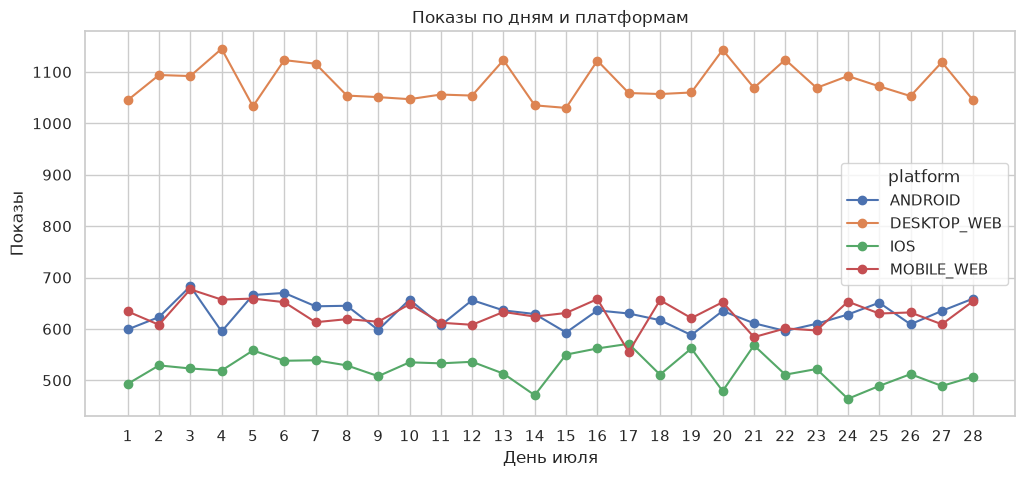

In [ ]:
imp_by_day_platform = (
    impressions
    .groupby(["day", "platform"], as_index=False)
    .size()
)

pivot = imp_by_day_platform.pivot(index="day", columns="platform", values="size")
pivot.index = pivot.index.astype(int)

ax = pivot.plot(figsize=(12, 5), marker="o")
ax.set_xticks(pivot.index)
ax.set_xlabel("День июля")
ax.set_ylabel("Показы")
ax.set_title("Показы по дням и платформам")
plt.show()

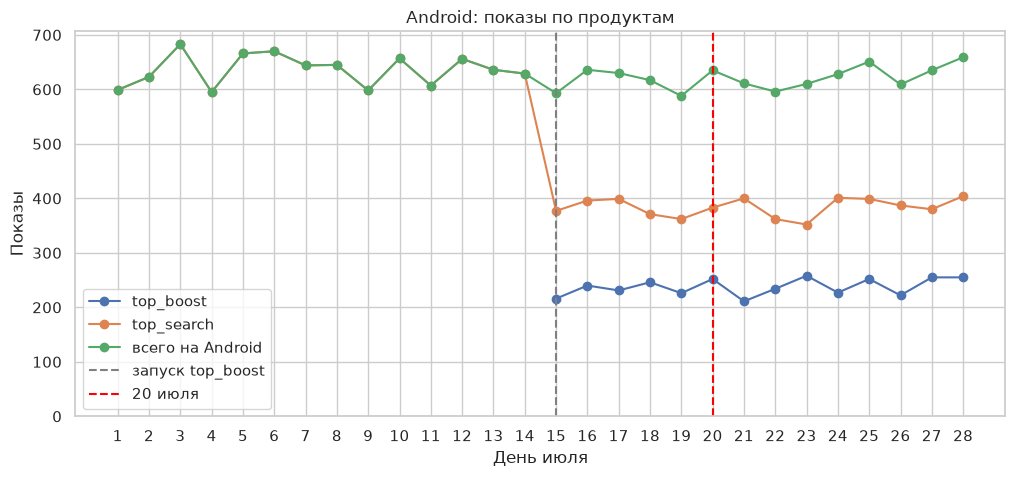

In [ ]:
android_imp = (
    impressions[impressions["platform"] == "ANDROID"]
    .groupby(["day", "product"], as_index=False)
    .size()
    .pivot(index="day", columns="product", values="size")
)
android_imp.index = android_imp.index.astype(int)
android_imp["всего на Android"] = android_imp.sum(axis=1)

ax = android_imp.plot(figsize=(12, 5), marker="o")
ax.axvline(15, color="gray", linestyle="--", label="запуск top_boost")
ax.axvline(20, color="red", linestyle="--", label="20 июля")
ax.set_xticks(android_imp.index)
ax.set_ylim(bottom=0)
ax.set_xlabel("День июля")
ax.set_ylabel("Показы")
ax.set_title("Android: показы по продуктам")
ax.legend()
plt.show()

- 20 июля провала показов нет ни у `top_search`, ни у Android в целом, поэтому всплеск CTR нельзя объяснить тем, что просел знаменатель
- Показы `top_search` снизились с 15 июля, а сумма по Android осталась прежней: похоже, `top_boost` забрал часть показов, поэтому CTR считаем по продуктам раздельно

In [ ]:
clicks_android_topsearch = sql("""
select
  count(*) as count_clicks,
  count(distinct cl.hhuid) as unique_hhuids,
  count(distinct cl.vacancy_id) as unique_vacancies,
  count(distinct cl.employer_id) as unique_employers
from clicks cl
where cl.platform = 'ANDROID'
  and cl.product = 'top_search'
  and cl.event_date = '2026-07-20'
""")

display(clicks_android_topsearch)

,count_clicks,unique_hhuids,unique_vacancies,unique_employers
0,36,36,36,36


- Клики пришли от разных пользователей, по разным вакансиям и работодателям, поэтому всплеск не создан одним ботом или популярной вакансией. Сбой в приложении это не исключает, он затронул бы всех пользователей

## 5. Всплеск CTR: интервал и распределение

In [ ]:
imp_to_click = sql("""
select
  imp.day,
  count(imp.impression_id) as cnt_impressions,
  count(cl.click_id) as cnt_clicks,
  count(cl.click_id) * 1.0 / count(imp.impression_id) as ctr
from impressions imp
left join clicks cl on imp.impression_id = cl.impression_id
where imp.platform = 'ANDROID'
  and imp.product = 'top_search'
group by imp.day
order by imp.day
""")

In [ ]:
def wilson_ci(successes, n, z=1.96):
    # 95% интервал Уилсона для доли: возвращает нижнюю и верхнюю границы
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return center - margin, center + margin


bounds = [wilson_ci(c, n) for c, n in zip(imp_to_click["cnt_clicks"], imp_to_click["cnt_impressions"])]
imp_to_click["ci_low"] = [b[0] for b in bounds]
imp_to_click["ci_high"] = [b[1] for b in bounds]


In [ ]:
def plot_ci(df, group, hue=None, value="ctr", low="ci_low", high="ci_high", title=None, colors=None):
    # Точка — значение метрики, отрезок — 95% интервал.
    # group — колонка (или список колонок), по которой строится строка графика,
    # hue — колонка, по которой точки одной строки раздвигаются и красятся
    colors = colors or {"20 июля": "tab:red", "контроль": "tab:blue"}
    labels = df[group].astype(str).agg(" · ".join, axis=1) if isinstance(group, list) else df[group].astype(str)
    order = list(dict.fromkeys(labels))
    hues = [] if hue is None else list(dict.fromkeys(df[hue]))

    fig, ax = plt.subplots(figsize=(9, 0.6 * len(order) + 1.2))
    for idx, row in df.iterrows():
        key = labels[idx] if hue is None else row[hue]
        shift = 0 if hue is None else (hues.index(row[hue]) - (len(hues) - 1) / 2) * 0.3
        y = order.index(labels[idx]) + shift
        color = colors.get(key, "tab:gray")
        ax.plot([row[low] * 100, row[high] * 100], [y, y], color=color, linewidth=2)
        ax.plot(row[value] * 100, y, "o", color=color)

    for h in hues:
        ax.plot([], [], "o-", color=colors.get(h, "tab:gray"), label=h)
    if hues:
        ax.legend(loc="lower right")
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_xlim(left=0)
    ax.set_xlabel(f"{value}, % (отрезок — 95% интервал)")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

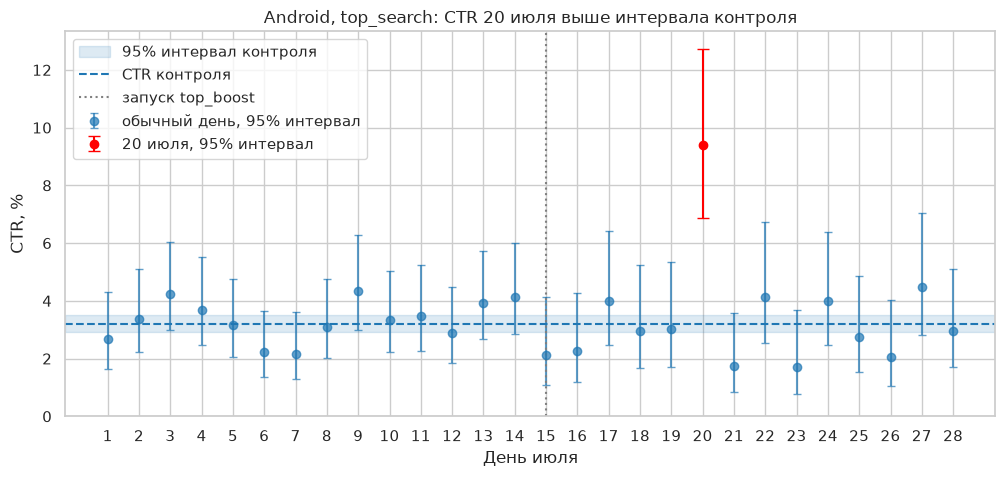

In [ ]:
is_spike = imp_to_click["day"] == "20"
control = imp_to_click[~is_spike]
control_clicks = control["cnt_clicks"].sum()
control_impressions = control["cnt_impressions"].sum()
control_ctr = control_clicks / control_impressions
control_low, control_high = wilson_ci(control_clicks, control_impressions)

days = imp_to_click["day"].astype(int)
ctr_pct = imp_to_click["ctr"] * 100
err_low = (imp_to_click["ctr"] - imp_to_click["ci_low"]) * 100
err_high = (imp_to_click["ci_high"] - imp_to_click["ctr"]) * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.axhspan(control_low * 100, control_high * 100, color="tab:blue", alpha=0.15, label="95% интервал контроля")
ax.axhline(control_ctr * 100, color="tab:blue", linestyle="--", label="CTR контроля")
ax.errorbar(
    days[~is_spike], ctr_pct[~is_spike],
    yerr=[err_low[~is_spike], err_high[~is_spike]],
    fmt="o", color="tab:blue", alpha=0.7, capsize=3, label="обычный день, 95% интервал",
)
ax.errorbar(
    days[is_spike], ctr_pct[is_spike],
    yerr=[err_low[is_spike], err_high[is_spike]],
    fmt="o", color="red", capsize=4, label="20 июля, 95% интервал",
)
ax.axvline(15, color="gray", linestyle=":", label="запуск top_boost")
ax.set_xticks(days)
ax.set_ylim(bottom=0)
ax.set_xlabel("День июля")
ax.set_ylabel("CTR, %")
ax.set_title("Android, top_search: CTR 20 июля выше интервала контроля")
ax.legend(loc="upper left")
plt.show()

- Всплеск подтверждён: CTR превышает порог из ТЗ, а интервалы дня и контроля не пересекаются, поэтому случайным колебанием это объяснить нельзя
- График не говорит о первоисточнике всплеска: это может быть ошибка логирования, а может быть кампания или ивент

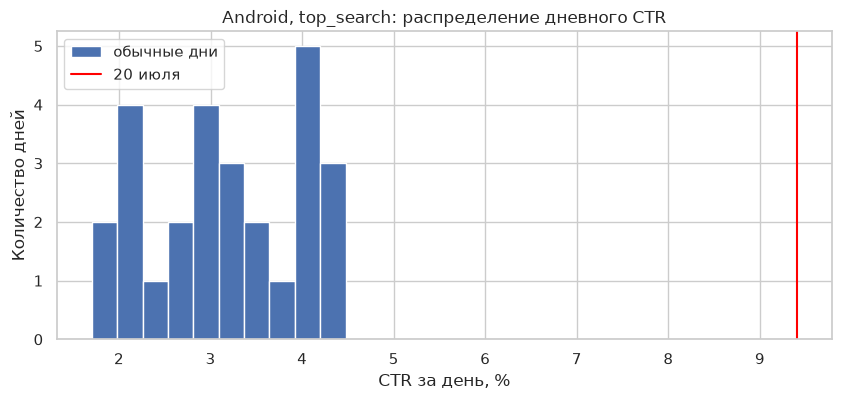

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(ctr_pct[~is_spike], bins=10, label="обычные дни")
ax.axvline(ctr_pct[is_spike].iloc[0], color="red", label="20 июля")

ax.set_xlabel("CTR за день, %")
ax.set_ylabel("Количество дней")
ax.set_title("Android, top_search: распределение дневного CTR")
ax.legend()
plt.show()

- 20 июля лежит далеко за пределами обычных дней и не отражает нормальный уровень CTR, поэтому исключаем его из базы CTR

## 6. Устойчивость роста

,period,count_impressions,count_clicks,ctr,ci_low,ci_high
0,до 20 июля,10813,352,0.032553,0.029371,0.036068
1,20 июля,383,36,0.093995,0.068668,0.127386
2,после 20 июля,3085,92,0.029822,0.024379,0.036434


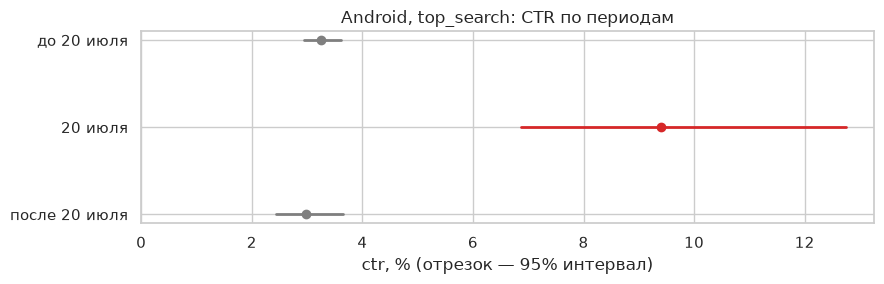

In [ ]:
stability = sql("""
select
  case
    when imp.day < '20' then 'до 20 июля'
    when imp.day = '20' then '20 июля'
    else 'после 20 июля'
  end as period,
  count(imp.impression_id) as count_impressions,
  count(cl.click_id) as count_clicks,
  count(cl.click_id) * 1.0 / count(imp.impression_id) as ctr
from impressions imp
left join clicks cl on imp.impression_id = cl.impression_id
where imp.platform = 'ANDROID'
  and imp.product = 'top_search'
group by 1
order by min(imp.day)
""")

bounds = [wilson_ci(c, n) for c, n in zip(stability["count_clicks"], stability["count_impressions"])]
stability["ci_low"] = [b[0] for b in bounds]
stability["ci_high"] = [b[1] for b in bounds]

display(stability)
plot_ci(stability, group="period", title="Android, top_search: CTR по периодам")

,period,count_impressions,count_clicks,ctr,ci_low,ci_high
0,до 20 июля,1905,55,0.028871,0.022248,0.037391
1,20 июля,383,36,0.093995,0.068668,0.127386
2,после 20 июля,3085,92,0.029822,0.024379,0.036434


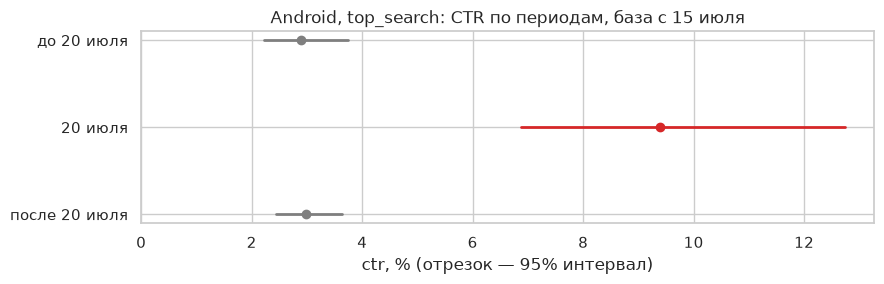

In [ ]:
stability_after_launch = sql("""
select
  case
    when imp.day < '20' then 'до 20 июля'
    when imp.day = '20' then '20 июля'
    else 'после 20 июля'
  end as period,
  count(imp.impression_id) as count_impressions,
  count(cl.click_id) as count_clicks,
  count(cl.click_id) * 1.0 / count(imp.impression_id) as ctr
from impressions imp
left join clicks cl on imp.impression_id = cl.impression_id
where imp.platform = 'ANDROID'
  and imp.product = 'top_search'
  and imp.day >= '15'
group by 1
order by min(imp.day)
""")

bounds = [
    wilson_ci(c, n)
    for c, n in zip(stability_after_launch["count_clicks"], stability_after_launch["count_impressions"])
]
stability_after_launch["ci_low"] = [b[0] for b in bounds]
stability_after_launch["ci_high"] = [b[1] for b in bounds]

display(stability_after_launch)
plot_ci(stability_after_launch, group="period", title="Android, top_search: CTR по периодам, база с 15 июля")

- Устойчивый рост не сохраняется, потому что интервалы периодов до и после всплеска пересекаются. Значит, всплеск разовый и устойчивого улучшения формата нет
- Вывод не зависит от выбранной базы: дни, взятые после запуска `top_boost`, не меняют картину

## 7. Где ещё вырос CTR: платформы и продукты

,platform,product,period,count_impressions,count_clicks,ctr,ci_low,ci_high
0,ANDROID,top_boost,20 июля,252,29,0.115079,0.081330,0.160388
1,ANDROID,top_boost,контроль,3073,136,0.044256,0.037536,0.052115
2,ANDROID,top_search,20 июля,383,36,0.093995,0.068668,0.127386
3,ANDROID,top_search,контроль,13898,444,0.031947,0.029150,0.035003
4,DESKTOP_WEB,top_boost,20 июля,429,34,0.079254,0.057267,0.108710
5,DESKTOP_WEB,top_boost,контроль,5425,390,0.071889,0.065314,0.079070
6,DESKTOP_WEB,top_search,20 июля,714,47,0.065826,0.049861,0.086439
7,DESKTOP_WEB,top_search,контроль,23614,1296,0.054883,0.052050,0.057861
8,IOS,top_boost,20 июля,186,8,0.043011,0.021953,0.082564
9,IOS,top_boost,контроль,2579,109,0.042264,0.035156,0.050734


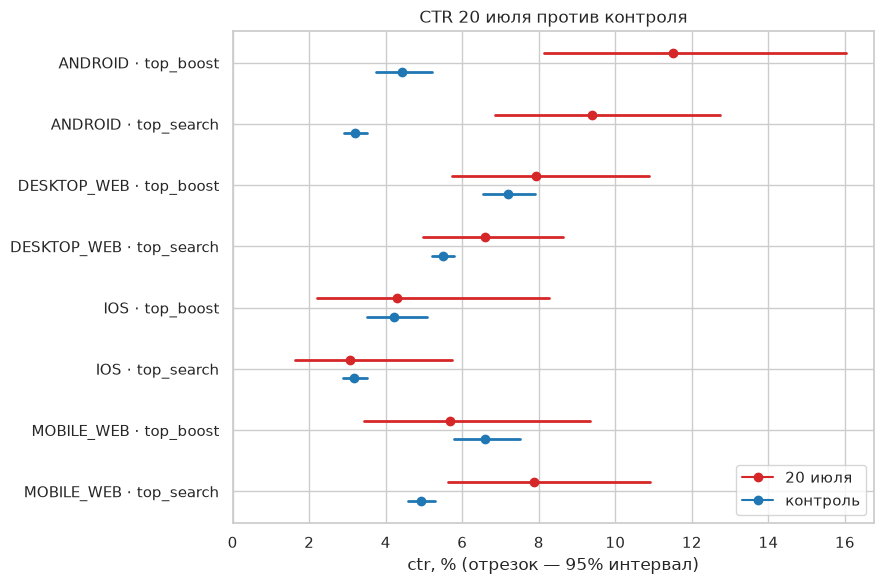

In [ ]:
spike_by_product = sql("""
select
  imp.platform,
  imp.product,
  case when imp.day = '20' then '20 июля' else 'контроль' end as period,
  count(imp.impression_id) as count_impressions,
  count(cl.click_id) as count_clicks,
  count(cl.click_id) * 1.0 / count(imp.impression_id) as ctr
from impressions imp
left join clicks cl on imp.impression_id = cl.impression_id
group by 1, 2, 3
order by 1, 2, 3
""")

bounds = [wilson_ci(c, n) for c, n in zip(spike_by_product["count_clicks"], spike_by_product["count_impressions"])]
spike_by_product["ci_low"] = [b[0] for b in bounds]
spike_by_product["ci_high"] = [b[1] for b in bounds]

display(spike_by_product)
plot_ci(spike_by_product, group=["platform", "product"], hue="period", title="CTR 20 июля против контроля")

- На Android CTR вырос у обоих продуктов
- На мобильном вебе вырос только `top_search`, но разрыв между интервалами очень маленький, это может быть случайностью
- На iOS и десктопе всплеска нет
- Критерий «рост связан с форматом» не выполнен, потому что на Android CTR вырос у обоих продуктов
- Причину стоит искать на уровне клиентского приложения Android, потому что на остальных платформах всплеска нет или он близок к случайности

## 8. Воронка после клика

,period,count_impressions,count_clicks,count_responses,click_to_resp,imp_to_resp,click_to_resp_low,click_to_resp_high,imp_to_resp_low,imp_to_resp_high
0,20 июля,383,36,4,0.111111,0.010444,0.044066,0.253151,0.004069,0.026542
1,контроль,13898,444,63,0.141892,0.004533,0.112500,0.177427,0.003545,0.005795


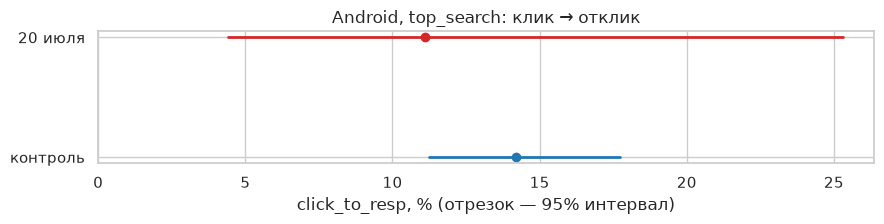

In [ ]:
funnel = sql("""
select
  case when imp.day = '20' then '20 июля' else 'контроль' end as period,
  count(imp.impression_id) as count_impressions,
  count(cl.click_id) as count_clicks,
  count(res.response_id) as count_responses,
  count(res.response_id) * 1.0 / count(cl.click_id) as click_to_resp,
  count(res.response_id) * 1.0 / count(imp.impression_id) as imp_to_resp
from impressions imp
left join clicks cl on imp.impression_id = cl.impression_id
left join responses res on cl.click_id = res.click_id
where imp.platform = 'ANDROID'
  and imp.product = 'top_search'
group by 1
order by 1
""")

bounds = [wilson_ci(c, n) for c, n in zip(funnel["count_responses"], funnel["count_clicks"])]
funnel["click_to_resp_low"] = [b[0] for b in bounds]
funnel["click_to_resp_high"] = [b[1] for b in bounds]

bounds = [wilson_ci(c, n) for c, n in zip(funnel["count_responses"], funnel["count_impressions"])]
funnel["imp_to_resp_low"] = [b[0] for b in bounds]
funnel["imp_to_resp_high"] = [b[1] for b in bounds]

display(funnel)
plot_ci(
    funnel, group="period", value="click_to_resp",
    low="click_to_resp_low", high="click_to_resp_high",
    title="Android, top_search: клик → отклик",
)

- Интервалы конверсии из клика в отклик за 20 июля и за контроль пересекаются, значит различие не обнаружено. Но откликов за день единицы, поэтому интервал очень широкий и разницу заметить почти невозможно
- То же самое с конверсией из показа в отклик: откликов слишком мало, чтобы что-то различить
- Конверсия заметно не упала, но откликов так мало, что ни один сценарий нельзя исключить (баг только с кликами, баг с кликами и откликами или реальное событие). Поэтому конверсия остаётся вспомогательной метрикой, а отличить баг от события помогут только сырые логи Android

## 9. Решение и ограничения

**Проверка критериев ТЗ**
- Всплеск подтверждён: да. CTR `top_search` на Android 20 июля выше контроля больше чем в 1,5 раза, интервалы дня и контроля не пересекаются
- Рост устойчивый: нет. Интервалы CTR за 21–28 и 1–19 июля пересекаются, то есть после всплеска CTR вернулся к обычному уровню. С базой только после запуска `top_boost` вывод тот же
- Рост связан с форматом: нет. На Android 20 июля вырос и `top_boost`, значит причина общая для приложения Android, а не в формате `top_search`. iOS, тоже мобильное приложение, всплеска не показал
- Технический след: не обнаружен. Нет повторных кликов на показ и кликов без показа, нет повторных откликов на клик и откликов без клика, провала показов 20 июля нет, клики пришли от разных пользователей, по разным вакансиям и работодателям

**Решение**
- Сейчас:
    - Формат `top_search` на Android не меняем, A/B-тест не планируем
    - Исключаем 20 июля из базы CTR, в отчётности день пока оставляем
    - Передаём разработке Android задачу проверить сырые логи кликов и откликов за 20 июля
- После проверки логов:
    - Баг подтвердился: чиним логирование и исключаем 20 июля из отчётности
    - Логи чистые: ищем событие 20 июля (релиз приложения, пуш, кампания) и фиксируем причину, формат не меняем
- Ответственный и срок: аналитик передаёт задачу разработке Android, проверка логов занимает до N дней

**Ограничения**
- Сырые логи Android не проверены, поэтому баг не подтверждён и не исключён
- В данных нет времени события, версии приложения и сессии, поэтому механизм всплеска не виден: нельзя проверить, совпал ли он с релизом или пушем
- Баг, который завышает и клики, и отклики, по этим данным не отличить от реального разового всплеска: метрики в обоих случаях выглядят одинаково
- Откликов за день мало, поэтому конверсии из клика и из показа в отклик оценены грубо и не помогают выбрать между сценариями
- На мобильном вебе CTR `top_search` 20 июля тоже выше нормы. При восьми сравнениях это может быть случайностью, но общую причину для мобильных пользователей это не исключает
- Запуск `top_boost` 15 июля изменил состав показов на Android. Проверка с базой после запуска дала тот же вывод, но период до 20 июля в ней короткий, и интервал широкий
- Порог роста в 1,5 раза задан условно
- Дневной отчёт `product_daily` для проверки не подходит: в нём нет разреза по платформам, поэтому всплеск на Android в нём не виден

## 10. Итоговая справка

In [ ]:
print(one_pager(
    decision=(
        "Формат top_search на Android не меняем. 20 июля исключаем из базы CTR и передаём сырые логи Android на проверку. Всплеск подтверждён, но он разовый и затронул оба продукта на Android, поэтому улучшением формата не объясняется"
    ),
    context=(
        "20 июля на Android кликабельность (CTR) top_search резко выше обычной. Нужно понять, ошибка ли это трекинга (тогда чиним логирование) или реальный эффект (тогда решаем, менять ли формат показа на Android)"
    ),
    what_done=(
        "- Проверили качество данных: дубли, пропуски, связность показов, кликов и откликов\n"
        "- Сравнили CTR 20 июля с контролем по интервалам Уилсона и распределению дневного CTR\n"
        "- Проверили устойчивость роста после 20 июля, в том числе с базой после запуска top_boost\n"
        "- Сравнили CTR 20 июля по платформам и продуктам\n"
        "- Посмотрели воронку после клика: клик → отклик и показ → отклик"
    ),
    result=(
        "- Всплеск подтверждён: CTR выше порога из ТЗ, интервалы дня и контроля не пересекаются\n"
        "- Рост неустойчивый: после 20 июля CTR вернулся к обычному уровню\n"
        "- Рост не связан с форматом: на Android вырос и top_boost, а на iOS всплеска нет\n"
        "- Технических следов нет: ни повторов, ни разрывов связей, ни провала показов, ни концентрации кликов\n"
        "- Конверсия после клика не отличает баг от реального события: откликов слишком мало\n"
        "- Ключевые графики: CTR по дням с 95% интервалом и распределение дневного CTR"
    ),
    limits=(
        "- Сырые логи Android не проверены, баг не подтверждён и не исключён\n"
        "- В данных нет времени события и версии приложения, механизм всплеска не виден\n"
        "- Баг, завышающий и клики, и отклики, статистически не отличить от реального разового всплеска\n"
        "- На мобильном вебе CTR top_search 20 июля тоже выше нормы, возможно случайно\n"
        "- Порог роста в 1,5 раза задан условно"
    ),
    action=(
        "- Аналитик передаёт разработке Android задачу проверить сырые логи кликов и откликов за 20 июля, срок проверки до N дней\n"
        "- Баг подтвердился: чиним логирование и исключаем 20 июля из отчётности\n"
        "- Логи чистые: ищем событие 20 июля (релиз, пуш, кампания) и фиксируем причину, формат не меняем"
    ),
))

ИТОГОВАЯ СПРАВКА

Решение:
Формат top_search на Android не меняем. 20 июля исключаем из базы CTR и передаём сырые логи Android на проверку. Всплеск подтверждён, но он разовый и затронул оба продукта на Android, поэтому улучшением формата не объясняется

Контекст:
20 июля на Android кликабельность (CTR) top_search резко выше обычной. Нужно понять, ошибка ли это трекинга (тогда чиним логирование) или реальный эффект (тогда решаем, менять ли формат показа на Android)

Что сделали:
- Проверили качество данных: дубли, пропуски, связность показов, кликов и откликов
- Сравнили CTR 20 июля с контролем по интервалам Уилсона и распределению дневного CTR
- Проверили устойчивость роста после 20 июля, в том числе с базой после запуска top_boost
- Сравнили CTR 20 июля по платформам и продуктам
- Посмотрели воронку после клика: клик → отклик и показ → отклик

Результат:
- Всплеск подтверждён: CTR выше порога из ТЗ, интервалы дня и контроля не пересекаются
- Рост неустойчивый: после 20 июля CTR вернул